# The paper's Figure 4 with trained random features: paper figure

Loads the runs written by `rf_newfig4.ipynb` and draws each run's endpoint against task diversity $T$ --
in-distribution and out-of-distribution side by side -- with the dMMSE and Ridge oracles and the degree-3
kernel floor of the same pools (the original figure's curve), in the style of the other figure notebooks.

Each point is a run's **weight-averaged endpoint** when it has one (`rf_newfig4` averages the weights
once the raw budget is spent, to get under the SGD noise ball), else its last evaluation. Bands are
$\pm 1$ standard deviation across the pools at each $T$ -- the raw spread, as in the original figure.
`ALIGN = "dmmse"` shifts every pool onto the mean pool at its $T$ by its dMMSE offset first, as the
n-curve notebooks do; the points stay the same and only the bands change.

## Colab setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os, subprocess

GIT_USER = "JoeyTurn"
GIT_REPO = "kernels_can_icl"
REPO_DIR = f"/content/{GIT_REPO}"

if not os.path.exists(REPO_DIR):
    r = subprocess.run(["git", "clone",
                        f"https://github.com/{GIT_USER}/{GIT_REPO}.git", REPO_DIR],
                       capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(r.stderr)
else:
    # Re-running the cell pulls latest changes instead of failing on "already exists"
    subprocess.run(["git", "-C", REPO_DIR, "pull"], check=True)

sys.path.insert(0, REPO_DIR)
sys.path.insert(0, f"{REPO_DIR}/expts/rf_scaling")

RESULTPATH = "/content/drive/MyDrive/results"
os.environ["RESULTPATH"] = RESULTPATH
os.makedirs(RESULTPATH, exist_ok=True)

if not os.path.exists("/content/expt-core"):
    subprocess.run(["git", "clone", "https://github.com/dkarkada/expt-core.git",
                    "/content/expt-core"], check=True)

sys.path.insert(0, "/content/expt-core")
from misc import rcsetup
rcsetup()

Mounted at /content/drive
GitHub PAT: ··········


In [2]:
import os, sys, glob, pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker

if os.path.exists("/content/kernels_can_icl"):
    # Colab: re-add the paths in case the runtime was restarted after the setup cell
    for p in ("/content/kernels_can_icl", "/content/kernels_can_icl/expts/rf_scaling", "/content/expt-core"):
        if p not in sys.path:
            sys.path.insert(0, p)
    RESULTPATH = os.environ.get("RESULTPATH", "/content/drive/MyDrive/results")
else:
    ROOT = Path.cwd()
    while ROOT != ROOT.parent and not (ROOT / "kernels_can_icl" / "__init__.py").exists():
        ROOT = ROOT.parent
    sys.path.insert(0, str(ROOT))
    sys.path.insert(0, str(ROOT / "expts" / "rf_scaling"))
    sys.path.insert(0, str(ROOT.parent / "expt-core"))
    RESULTPATH = str(ROOT / "expts" / "rf_scaling" / "results")

try:
    from misc import rcsetup
    rcsetup()
except ImportError:                     # the same settings as expt-core's misc.rcsetup
    plt.rc("figure", dpi=120, facecolor=(1, 1, 1))
    plt.rc("font", family="stixgeneral", size=12)
    plt.rc("axes", facecolor=(1, .99, .95), titlesize=12)
    plt.rc("mathtext", fontset="cm")
    plt.rc("pdf", fonttype=42)
    plt.rc("ps", fonttype=42)
print("RESULTPATH:", RESULTPATH)

RESULTPATH: /content/drive/MyDrive/results


## Settings

`RUNS` maps a legend label to a source: `None` takes the newest `rf_newfig4_*_summary.pkl` -- the notebook
writes it after a pass over every T, so it lists all the runs -- a path ending `.pkl` takes that summary, and
any other string picks a tag (or part of one) and reads the per-run checkpoints instead, e.g. mid-sweep.

In [52]:
RUNS         = {"Random Features\n Network": None}   # label -> None (newest summary), a
                                      #   *_summary.pkl, or a tag (reads the per-run checkpoints)
SIDES        = ("id", "ood")          # one panel per side
SWEEP_TS     = None                   # which T to show (None = every T with a run)
YSCALE       = "linear"               # "log" as in fig 2
YLIM         = {}                     # e.g. {"ood": (0.0, 1.3)}; default fits the curves and the oracles
SD_BAND      = True                   # +/- 1 standard deviation across the pools at each T
ORA_BAND     = True                   # shade that spread on the oracle lines too
ALIGN        = None                   # "dmmse" shifts each pool by Delta_i = dMMSE_i - dMMSE_baseline first.
                                      #   With the mean baseline the points are the same either way; only the
                                      #   bands change, and the Ridge band then inherits dMMSE's pool spread
ALIGN_BASE   = None                 # baseline per T when aligning: the "mean" pool or the "first"
FONTSIZE     = 16                     # tick labels; axis labels +2, the legend -1
TOP_FREE     = 0.25                   # keep this much of the axis clear under an upper legend
XLABEL       = r"Task Diversity $T$"
FLOOR        = True                   # the degree-3 kernel floor of the same pools, dashed
FLOOR_BAND   = None                   # (rf_finality only: the floor's spread over pool draws)
LEGEND_LOC   = "center right"
LEGEND_PANEL = -1                     # the legend goes in the last panel (OOD)
PARAM_BOX    = True                   # d, L, eps^2, sigma_x^2 in the first panel
PHASES       = True                   # shade the task-diversity regimes, in fig 1's wash and ink
PHASE_T      = "d+1"                  # band boundaries in T: "d+1" (where the pool first spans the task
                                      #   space), a T, or a list of them. (1.5,) puts T=1 alone in the
                                      #   first band; None = no bands
PHASE_T = (1.5, 3)
PHASE_COLORS = ("#7fb3d5", "#7ec0ba", "#7dcea0")#, "#f0b27a")   # blue, green, orange -- fig 1's phases 1, 2, 3
PHASE_ALPHA, PHASE_DARKEN, PHASE_SAT, PHASE_EDGE_LW = 0.28, 0.78, 1.75, 0

In [53]:
import re

CKPT_RE = re.compile(r"^rf_newfig4_(.*)_T(\d+)_([ts])(\d+)\.pt$")


def config_info(config=None, fp=None):
    """d, L, eps^2 and sigma_x^2 for the parameter box, from a summary's config or a checkpoint fingerprint."""
    if config:
        return dict(dim=config["dim"], L=config["L_cfg"], eps=config["sigma_sq"], sigma_x2=config["sigma_x2"])
    return dict(dim=fp.get("dim"), L=fp.get("pairs", 0) + 1, eps=fp.get("eps"), sigma_x2=fp.get("sigma_x2"))


def load_summary(path):
    """(records, info, config, floor_dist) from a summary pickle."""
    with open(path, "rb") as f:
        S = pickle.load(f)
    info = dict(M=S.get("M", S.get("P")), batch=S.get("batch"), width=S.get("width"))
    return S["records"], info, config_info(config=S.get("config")), S.get("floor_dist")


def load_tag(tag, resultpath):
    """(records, info, config, None) from one tag's per-run checkpoints. A `_s<seed>` file is a
    representative pool chosen in place of trial 0's default draw (rf_finality), so where both exist
    it takes trial 0's place -- the default draw's file stays on disk but is not part of the figure."""
    import torch                            # only the checkpoints need it
    best = {}
    for path in glob.glob(os.path.join(resultpath, "rf_newfig4_*_T*_*.pt")):
        m = CKPT_RE.match(os.path.basename(path))
        if not m or m.group(1) != tag:
            continue
        T, kind, k = int(m.group(2)), m.group(3), int(m.group(4))
        key, rank = (T, k if kind == "t" else 0), kind == "s"
        if key not in best or rank > best[key][0]:
            best[key] = (rank, path)
    records, fp = [], {}
    for (T, trial), (_, path) in sorted(best.items()):
        st = torch.load(path, map_location="cpu", weights_only=False)
        fp = st["fingerprint"]
        records.append(dict(T=T, trial=trial, seed=fp.get("seed"), step=int(st["step"]), curve=st["curve"],
                            avg_curve=list((st.get("avg") or {}).get("curve", [])), **st["ref"]))
    info = dict(M=fp.get("M", fp.get("P")), batch=fp.get("batch"), width=fp.get("width"))
    return records, info, config_info(fp=fp), None


def load_sweep(entry, resultpath):
    """(source, records, info, config, floor_dist, tag) for one RUNS entry: None = the newest summary
    pickle (preferring full runs over _smoke ones), a path ending .pkl = that summary, anything else =
    a tag, or any part of one, whose per-run checkpoints are read instead."""
    if entry is None or entry.endswith(".pkl"):
        if entry is None:
            paths = glob.glob(os.path.join(resultpath, "rf_newfig4_*_summary.pkl"))
            if not paths:
                raise FileNotFoundError(f"no rf_newfig4_*_summary.pkl in {resultpath}; "
                                        "give a tag to read the per-run checkpoints instead")
            entry = max([p for p in paths if "_smoke" not in os.path.basename(p)] or paths,
                        key=os.path.getmtime)
        path = entry if os.path.isabs(entry) or os.path.exists(entry) else os.path.join(resultpath, entry)
        tag = os.path.basename(path).removeprefix("rf_newfig4_").removesuffix("_summary.pkl")
        return (os.path.basename(path),) + load_summary(path) + (tag,)
    files = glob.glob(os.path.join(resultpath, "rf_newfig4_*_T*_*.pt"))
    tags = {m.group(1) for p in files if (m := CKPT_RE.match(os.path.basename(p)))}
    hits = [t for t in tags if entry in t]
    if not hits:
        raise FileNotFoundError(f"no checkpoints matching {entry!r} in {resultpath} (tags: {sorted(tags)})")
    newest = lambda t: max(os.path.getmtime(p) for p in files if os.path.basename(p).startswith(f"rf_newfig4_{t}_T"))
    tag = max(hits, key=newest)
    return ("per-run checkpoints",) + load_tag(tag, resultpath) + (tag,)


runs, metas = [], []
for label, entry in RUNS.items():
    src, records, info, config, floor_dist, tag = load_sweep(entry, RESULTPATH)
    runs.append((label, records))
    metas.append(dict(tag=tag, config=config, floor_dist=floor_dist))
    print(f"{label}: {tag}  ({src})")
    bits = [f"M={info['M']:,}" if info.get("M") else "", f"batch {info['batch']}" if info.get("batch") else "",
            f"width {info['width']:.3g}" if info.get("width") else ""]
    print("    " + "   ".join(b for b in bits if b))
    for T in sorted({r["T"] for r in records}):
        rs = [r for r in records if r["T"] == T]
        avg = sum(bool(r.get("avg_curve")) for r in rs)
        print(f"    T={T:>5}: {len(rs)} run(s)" + (f", {avg} weight-averaged" if avg else ""))

TAG, CONFIG, FLOOR_DIST = metas[0]["tag"], metas[0]["config"], metas[0]["floor_dist"]

Random Features
 Network: d8p15e0.25_sx0.03125_normal_M16384_b256_w1.5  (rf_newfig4_d8p15e0.25_sx0.03125_normal_M16384_b256_w1.5_summary.pkl)
    M=16,384   batch 256   width 7
    T=    1: 3 run(s), 3 weight-averaged
    T=    2: 3 run(s), 3 weight-averaged
    T=    4: 3 run(s), 3 weight-averaged
    T=    8: 3 run(s), 3 weight-averaged
    T=   16: 3 run(s), 3 weight-averaged
    T=   32: 3 run(s), 3 weight-averaged
    T=   64: 3 run(s), 3 weight-averaged
    T=  128: 3 run(s), 3 weight-averaged
    T=  256: 3 run(s), 3 weight-averaged
    T=  512: 3 run(s), 3 weight-averaged
    T= 1024: 3 run(s), 3 weight-averaged


## Figure

In [54]:
# figure 2's palette, in series order
STYLES = [("#0F3087", "o"), ("#6C63F0", "s"), ("#D97706", "^"), ("#C2185B", "D"), ("#2E7D32", "v")]
ORACLES = (("dmmse", "Memorizing Solution", "#DC143C", 2.0), ("ridge", "Generalizing Solution", "black", 2.8))
SIDE_NAME = {"ood": "OOD", "id": "ID"}


def pool_offsets(records, T, side, align="dmmse", base="first"):
    """{trial: Delta_i} putting every trial's pool on one baseline level, and that baseline's dMMSE.

    Each trial draws its own task pool (the seed is keyed on T *and* the trial), and at small T the pool
    sets the level of the whole curve -- pools whose dMMSE differs by 0.1 shift their curves by about
    that much. Averaging the raw curves then inflates the band and flattens the dip. So everything a
    trial produces is shifted by Delta_i = dMMSE_i - dMMSE_baseline before it is averaged, which puts
    every pool on the baseline pool's level; the plotted dMMSE line lands exactly on that baseline.
    align=None turns this off (raw averaging). base: "first" trial's pool, or the "mean" over pools.
    """
    recs = sorted((r for r in records if r["T"] == T), key=lambda r: r.get("trial", 0))
    dm = [r["oracles"][f"dmmse_{side}"] for r in recs]
    if not dm:
        return {}, np.nan
    if not align:
        return {}, float(np.mean(dm))
    b = dm[0] if base == "first" else float(np.mean(dm))
    return {r.get("trial", i): d - b for i, (r, d) in enumerate(zip(recs, dm))}, b


def curve_stats(records, T, side, band=True, offs=None):
    """(n, mean, sd) of the measured curve at task diversity T, over trials, each shifted onto the
    baseline pool by `offs` (see pool_offsets). sd is the sample standard deviation across trials
    (never the standard error); 0 with one trial or band=False."""
    offs = offs or {}
    recs = [r for r in records if r["T"] == T and r.get("curve")]
    ns = sorted({c["n"] for r in recs for c in r["curve"]})
    m, s = [], []
    for n in ns:
        v = np.array([c[side] - offs.get(r.get("trial", 0), 0.0)
                      for r in recs for c in r["curve"] if c["n"] == n], float)
        v = v[np.isfinite(v)]
        m.append(v.mean() if v.size else np.nan)
        s.append(v.std(ddof=1) if band and v.size > 1 else 0.0)
    return np.array(ns, float), np.array(m), np.array(s)


def oracle_stats(records, T, key, side, offs=None, band=True):
    """(mean, sd) of an oracle ('dmmse' or 'ridge') over trials, on the same shifted pools as the
    curves. Note that aligning on the dMMSE makes every trial's dMMSE the baseline, so its sd is then
    exactly 0 -- the pool spread has moved into the curves, which are now read against their own pool."""
    offs = offs or {}
    v = np.array([r["oracles"][f"{key}_{side}"] - offs.get(r.get("trial", 0), 0.0)
                  for r in records if r["T"] == T], float)
    return float(v.mean()), float(v.std(ddof=1)) if band and v.size > 1 else 0.0


def theory_curve(records, T, side, offs=None):
    """(n, trial mean) of the theory curve record["pred"], shifted like the curves; None if absent."""
    offs = offs or {}
    recs = [r for r in records if r["T"] == T and r.get("pred")]
    if not recs:
        return None
    n = np.asarray(recs[0]["pred"]["n"], float)
    ys = [np.asarray(r["pred"][side], float) - offs.get(r.get("trial", 0), 0.0)
          for r in recs if len(r["pred"][side]) == len(n)]
    return n, np.mean(ys, 0)


def log_ticks(lo, hi, max_ticks=7):
    """Round tick values for a log axis: the finest of {1,1.2,1.5,2,3,4,5,6,8}, {1,2,3,5}, {1,2,5}, {1}
    per decade that puts at most max_ticks inside [lo, hi]."""
    decades = 10.0 ** np.arange(np.floor(np.log10(lo)), np.ceil(np.log10(hi)) + 1)
    for mant in ((1, 1.2, 1.5, 2, 3, 4, 5, 6, 8), (1, 2, 3, 5), (1, 2, 5), (1,)):
        vals = [float(f"{m * d:.6g}") for d in decades for m in mant]
        vals = [v for v in vals if lo <= v <= hi]
        if 2 <= len(vals) <= max_ticks:
            return vals
    return None


def default_ylim(ax, xys, yscale, top_free, x_from=0.38):
    """y-limits that fit everything drawn, raised if needed so the top `top_free` of the axis is
    clear of data right of x-fraction `x_from` -- where the T label and an upper-right legend sit.
    The x-limits must already be set (call after plotting)."""
    log = yscale == "log"
    ok = lambda y: np.isfinite(y) & (y > 0) if log else np.isfinite(y)
    ys = np.concatenate([y[ok(y)] for _, y in xys])
    if log:
        lo, hi = ys.min() / 1.1, ys.max() * 1.08
    else:
        pad = 0.06 * (ys.max() - ys.min())
        lo, hi = ys.min() - pad, ys.max() + pad
    x0, x1 = np.log10(ax.get_xlim())
    under = [y[ok(y) & ((np.log10(n) - x0) / (x1 - x0) >= x_from)] if n is not None else y[ok(y)]
             for n, y in xys]
    top = max((u.max() for u in under if u.size), default=None)
    if top is not None and 0 < top_free < 1:
        if log:
            hi = max(hi, lo * (top / lo) ** (1.0 / (1.0 - top_free)))
        else:
            hi = max(hi, lo + (top - lo) / (1.0 - top_free))
    return lo, hi


def finish_panel(ax, xys, side, yscale, ylim_side, top_free, fontsize, xlabel, label, floor_y):
    """Shared panel cosmetics: y-limits, round log ticks, tick and label sizes, and the in-plot label.
    Returns the axes-fraction height of floor_y, which is what a lower legend has to clear."""
    ax.set_yscale(yscale)
    lo, hi = ylim_side if ylim_side else default_ylim(ax, xys, yscale, top_free)
    ax.set_ylim(lo, hi)
    if yscale == "log":
        vals = log_ticks(lo, hi)
        if vals:
            ax.yaxis.set_major_locator(ticker.FixedLocator(vals))
            ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{v:g}"))
            ax.yaxis.set_minor_locator(ticker.LogLocator(subs="all"))
            ax.yaxis.set_minor_formatter(ticker.NullFormatter())
    ax.tick_params(which="major", length=6, width=1.0, labelsize=fontsize)
    ax.tick_params(which="minor", length=3.5, width=0.8)
    ax.grid(axis="x", which="major", alpha=0.15, lw=0.8)
    if label:
        ax.text(0.5, 0.965, label, transform=ax.transAxes, ha="center", va="top",
                fontsize=fontsize + 6)
    # ax.set_xlabel(xlabel, fontsize=fontsize + 2)
    # ax.set_ylabel(f"{SIDE_NAME[side]} Test MSE", fontsize=fontsize + 2)
    return ax.transAxes.inverted().transform(ax.transData.transform((ax.get_xlim()[0], floor_y)))[1]


# def place_legend(ax, floor_frac, legend_loc, fontsize):
#     """The legend, kept off an oracle line that runs along the bottom of the axes."""
#     leg = dict(loc=legend_loc, framealpha=1.0, fontsize=fontsize)
#     if legend_loc.startswith("lower") and 0.0 <= floor_frac < 0.2:
#         leg["bbox_to_anchor"] = ({"left": 0.0, "center": 0.5, "right": 1.0}[legend_loc.split()[-1]],
#                                  floor_frac + 0.01)
#     ax.legend(**leg)

def place_legend(ax, floor_frac, legend_loc, fontsize, custom_bbox=None):
    """The legend, kept off an oracle line that runs along the bottom of the axes."""
    leg = dict(loc=legend_loc, framealpha=0.0, fontsize=fontsize)

    # Apply custom precise placement if provided
    if custom_bbox:
        leg["bbox_to_anchor"] = custom_bbox

    if legend_loc.startswith("lower") and 0.0 <= floor_frac < 0.2:
        leg["bbox_to_anchor"] = ({"left": 0.0, "center": 0.5, "right": 1.0}[legend_loc.split()[-1]],
                                 floor_frac + 0.01)
    ax.legend(**leg)


def draw_n_panel(ax, runs, T, side, yscale="log", ylim=None, band=True, theory=False,
                 legend_loc="upper right", xlabel="$n$", top_free=0.25, ms=6, fontsize=15, t_label=True,
                 align="dmmse", align_base="first", oracle_band=True):
    """One n-curve panel on `ax`: each run's measured curve, the dMMSE and Ridge oracles, and the
    theory curve if theory=True. Returns the axes-fraction height of the lowest oracle line, for
    place_legend. Arguments as plot_fig2 (ylim is the {side: (lo, hi)} dict)."""
    ylim = ylim or {}
    if not (t_label or legend_loc.startswith("upper")):
        top_free = 0.0                      # nothing sits along the top to keep clear of
    ref = next(recs for _, recs in runs if any(r["T"] == T for r in recs))
    xys = []                                # (n, y) of everything drawn; n=None for the oracle lines
    for k, (label, records) in enumerate(runs):
        offs, _ = pool_offsets(records, T, side, align, align_base)
        n, m, s = curve_stats(records, T, side, band, offs)
        if not len(n):
            continue
        col, mk = STYLES[k % len(STYLES)]
        if np.any(s > 0):
            ax.fill_between(n, m - s, m + s, color=col, alpha=0.2, lw=0, zorder=3)
        ax.plot(n, m, "-", marker=mk, color=col, lw=2.0, ms=ms, label=label, zorder=4)
        xys += [(n, m - s), (n, m + s)]
    roffs, _ = pool_offsets(ref, T, side, align, align_base)
    th = theory_curve(ref, T, side, roffs) if theory else None
    if th is not None:
        ax.plot(*th, "--", color="0.3", lw=2.0, label="Theory", zorder=3.5)
        xys.append(th)
    oys = []
    for key, lab, col, lw in ORACLES:
        y, sd = oracle_stats(ref, T, key, side, roffs, band)
        ax.axhline(y, color=col, lw=lw, label=lab, zorder=2)
        if oracle_band and sd > 0:
            ax.axhspan(y - sd, y + sd, color=col, alpha=0.15, lw=0, zorder=1)
        lo_y = y - sd if oracle_band else y
        xys.append((None, np.array([lo_y, y + sd if oracle_band else y])))
        oys.append(lo_y)
    ax.set_xscale("log")
    return finish_panel(ax, xys, side, yscale, ylim.get(side), top_free, fontsize, xlabel,
                        f"T={T}" if t_label else None, min(oys))


def plot_fig2(runs, T, sides=("ood",), yscale="log", ylim=None, band=True, theory=False,
              legend_loc="upper right", xlabel="$n$", top_free=0.25, ms=6, fontsize=15, t_label=True,
              align="dmmse", align_base="first", oracle_band=True):
    """Measured error against n at task diversity T, one panel per side, figure-2 style.

    runs: [(label, records)]; each run is one coloured series, with a +/- 1 standard deviation band
    across its trials if `band`. The oracle lines -- and the theory curve, if theory=True -- come from
    the first run that has T. align/align_base: put each trial's pool on one baseline level before
    averaging (see pool_offsets); None averages the raw curves. top_free: fraction of the axis height
    kept clear of data under the T label and an upper legend when the y-limits are automatic (0 = fit
    tight). fontsize: tick labels and legend; axis labels are 2pt larger, the T label 6pt.
    """
    fig, axs = plt.subplots(1, len(sides), figsize=(6.0 * len(sides), 4.5), squeeze=False)
    axs = axs[0]
    floors = [draw_n_panel(ax, runs, T, side, yscale, ylim, band, theory, legend_loc, xlabel, top_free,
                           ms, fontsize, t_label, align, align_base, oracle_band)
              for ax, side in zip(axs, sides)]
    place_legend(axs[0], floors[0], legend_loc, fontsize)
    fig.tight_layout()
    return fig, axs

def value_at(record, n, side, offs=None, tol=2.0):
    """The record's curve value nearest n in log distance, shifted onto the baseline pool.

    nan if the nearest point is further than a factor `tol` from n: a run that stopped early should
    drop out of the read-off rather than quietly contribute its own endpoint instead.
    """
    row = min(record["curve"], key=lambda c: abs(np.log(c["n"]) - np.log(n)))
    if abs(np.log(row["n"]) - np.log(n)) > np.log(tol):
        return np.nan
    return row[side] - (offs or {}).get(record.get("trial", 0), 0.0)


def last_n(records):
    """The largest n on the loaded curves: the default read-off point for the T sweep."""
    return max(c["n"] for r in records for c in r.get("curve", []))


def sweep_stats(records, Ts, side, n_at, band=True, align="dmmse", align_base="first"):
    """(T, mean, sd) of the measured curve read at n_at, one point per T, over trials."""
    out, m, s = [], [], []
    for T in Ts:
        recs = [r for r in records if r["T"] == T and r.get("curve")]
        if not recs:
            continue
        offs, _ = pool_offsets(records, T, side, align, align_base)
        v = np.array([value_at(r, n_at, side, offs) for r in recs], float)
        v = v[np.isfinite(v)]
        if not v.size:
            continue
        out.append(T)
        m.append(v.mean())
        s.append(v.std(ddof=1) if band and v.size > 1 else 0.0)
    return np.array(out, float), np.array(m), np.array(s)


def plot_T_sweep(runs, Ts=None, n_at=None, sides=("ood",), yscale="log", ylim=None, band=True,
                 legend_loc="lower left", xlabel="Task Diversity $T$", top_free=0.25, ms=6,
                 fontsize=15, n_label=True, align="dmmse", align_base="first", oracle_band=True):
    """The same curves read at one n and swept over T, one panel per side, in the same style.

    Ts: which T to show (default every T in the runs). n_at: where each curve is read (default its
    last point); the nearest point in log n is used. The oracles depend on T, so here they are lines
    over T, taken from the first run, on the same shifted pools as the curves.
    """
    ylim = ylim or {}
    ref = runs[0][1]
    Ts = sorted({r["T"] for _, recs in runs for r in recs}) if Ts is None else list(Ts)
    n_at = n_at or last_n(ref)
    if not (n_label or legend_loc.startswith("upper")):
        top_free = 0.0
    floors = []
    fig, axs = plt.subplots(1, len(sides), figsize=(6.0 * len(sides), 4.5), squeeze=False)
    axs = axs[0]
    for ax, side in zip(axs, sides):
        xys = []
        for k, (label, records) in enumerate(runs):
            t, m, sd = sweep_stats(records, Ts, side, n_at, band, align, align_base)
            if not len(t):
                continue
            col, mk = STYLES[k % len(STYLES)]
            if np.any(sd > 0):
                ax.fill_between(t, m - sd, m + sd, color=col, alpha=0.2, lw=0, zorder=3)
            ax.plot(t, m, "-", marker=mk, color=col, lw=2.0, ms=ms, label=label, zorder=4)
            xys += [(t, m - sd), (t, m + sd)]
        oys, ts = [], [T for T in Ts if any(r["T"] == T for r in ref)]
        tf = np.array(ts, float)
        for key, lab, col, lw in ORACLES:
            ms_ = [oracle_stats(ref, T, key, side, pool_offsets(ref, T, side, align, align_base)[0],
                                band) for T in ts]
            y = np.array([a for a, _ in ms_])
            sd = np.array([b for _, b in ms_]) if oracle_band else np.zeros(len(ms_))
            ax.plot(tf, y, "-", color=col, lw=lw, label=lab, zorder=2,
                    marker=("o" if key == "dmmse" else None), ms=ms - 1, mec=col, mfc=col)
            # ax.plot(tf, y, "-", color=col, lw=lw, label=lab, zorder=2)
            if np.any(sd > 0):
                ax.fill_between(tf, y - sd, y + sd, color=col, alpha=0.15, lw=0, zorder=1)
            xys += [(tf, y - sd), (tf, y + sd)]
            oys += list(y - sd)
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_locator(ticker.FixedLocator(Ts))
        ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{v:g}"))
        ax.xaxis.set_minor_locator(ticker.NullLocator())
        floors.append(finish_panel(ax, xys, side, yscale, ylim.get(side), top_free, fontsize, xlabel,
                                   f"n={n_at:,.0f}" if n_label else None, min(oys, default=np.nan)))
    place_legend(axs[0], floors[0], legend_loc, fontsize)
    fig.tight_layout()
    return fig, axs

In [55]:
def final_point(r):
    """What a T-sweep plots for a run: its weight-averaged endpoint if it has one, else its last evaluation."""
    return r["avg_curve"][-1] if r.get("avg_curve") else r["curve"][-1]


MODEL = lambda r, side: final_point(r)[side]
# FLOOR3 = lambda r, side: r["floor3"][side] if "floor3" in r else np.nan


def oracle_of(key):
    return lambda r, side: r["oracles"][f"{key}_{side}"]


def sweep_Ts(runs, Ts=None):
    """The T with at least one run, optionally restricted to Ts."""
    have = sorted({r["T"] for _, recs in runs for r in recs if r.get("curve")})
    return have if Ts is None else [T for T in have if T in Ts]


def _corner(ax, text, loc="upper left", fontsize=12):
    x, ha = (0.98, "right") if "right" in loc else (0.02, "left")
    y, va = (0.97, "top") if "upper" in loc else (0.03, "bottom")
    ax.text(x, y, text, ha=ha, va=va, transform=ax.transAxes,
            fontsize=fontsize, color="xkcd:dark gray", linespacing=1.35)


def per_T(records, Ts, fn, side, band=True, align="dmmse", align_base="mean"):
    """(T, mean, sd) over each T's runs of fn(record, side). Each run is first shifted onto the baseline
    pool by its dMMSE offset (pool_offsets), as in the n-curve figures; sd is the sample SD across runs."""
    out, m, s = [], [], []
    for T in Ts:
        recs = [r for r in records if r["T"] == T and r.get("curve")]
        if not recs:
            continue
        offs, _ = pool_offsets(recs, T, side, align, align_base)
        v = np.array([fn(r, side) - offs.get(r.get("trial", 0), 0.0) for r in recs], float)
        v = v[np.isfinite(v)]
        if not v.size:
            continue
        out.append(T)
        m.append(v.mean())
        s.append(v.std(ddof=1) if band and v.size > 1 else 0.0)
    return np.array(out, float), np.array(m), np.array(s)


def pow2_ticks(ax, Ts):
    """A log-2 T axis labelled 2^k; every other power once there would be more than seven."""
    ks = range(int(np.floor(np.log2(min(Ts)))), int(np.ceil(np.log2(max(Ts)))) + 1)
    ticks = [2.0 ** k for k in ks]
    if len(ticks) > 7:
        ticks = ticks[::2]
    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_locator(ticker.FixedLocator(ticks))
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"$2^{{{int(round(np.log2(v)))}}}$"))
    ax.xaxis.set_minor_locator(ticker.NullLocator())


def param_text(config):
    """The setting for a parameter box: d, L on one line, eps^2 and sigma_x^2 on the next."""
    if not config or config.get("dim") is None:
        return None
    sx = config.get("sigma_x2")
    sx_s = "?" if not sx else (f"1/{round(1 / sx)}" if abs(1 / sx - round(1 / sx)) < 1e-6 else f"{sx:g}")
    return (f"$d={config['dim']}$,  $L={config['L']}$ "
            + rf"$\epsilon^2={config['eps']:g}$")



# --- fig 1's phase shading, laid out in T: one source colour per band -> a pale wash and a darker ink -
PHASE_COLORS_DEF = ("#7fb3d5", "#7dcea0", "#f0b27a")
PHASE_ALPHA_DEF, PHASE_DARKEN_DEF, PHASE_SAT_DEF, PHASE_EDGE_LW_DEF = 0.28, 0.78, 1.75, 1.2


def phase_inks(colors, alpha=PHASE_ALPHA_DEF, darken=PHASE_DARKEN_DEF, sat=PHASE_SAT_DEF):
    """(wash, ink) per band, as the phase diagram builds them: the ink is the source colour with its
    saturation multiplied and its value cut; the wash -- the panel fill -- is that ink over white."""
    import colorsys
    import matplotlib.colors as mcolors
    wash, ink = [], []
    for c in colors:
        h, sat0, val = colorsys.rgb_to_hsv(*mcolors.to_rgb(c))
        k = colorsys.hsv_to_rgb(h, min(1.0, sat0 * sat), val * darken)
        ink.append(k)
        wash.append(tuple(1 - alpha + alpha * ch for ch in k))
    return wash, ink


def phase_spans(edges, xlim):
    """[(lo, hi)] for each band, clipped to the axis."""
    inner = [e for e in edges if xlim[0] < e < xlim[1]]
    bounds = [xlim[0]] + sorted(inner) + [xlim[1]]
    return list(zip(bounds[:-1], bounds[1:]))


def draw_phases(ax, spans, wash, ink=None, edge_lw=PHASE_EDGE_LW_DEF):
    """Fill each band with its wash, behind everything, and rule the boundaries in the ink."""
    for i, ((a, b), w) in enumerate(zip(spans, wash)):
        ax.axvspan(a, b, color=w, lw=0, zorder=-20)
        if i and ink is not None and edge_lw:
            ax.axvline(a, color=ink[i], lw=edge_lw, alpha=0.85, zorder=-19)


def phase_edges_for(spec, Ts, dim=None):
    """Band edges in T. spec: "d+1" -- the pool first spans the task space -- a single T, or a list of
    them; (1.5,) puts T=1 alone in the first band. Each edge is moved to the geometric midpoint of the
    two swept T it falls between, so on the log-2 axis the boundary sits between ticks, not on one."""
    if spec is None:
        return []
    if isinstance(spec, str):
        if dim is None:
            print(f"phase edge {spec!r} needs the run's d; no bands drawn")
            return []
        spec = [dim + 1]
    elif np.isscalar(spec):
        spec = [float(spec)]
    out = []
    for e in spec:
        lo = [t for t in Ts if t < e]
        hi = [t for t in Ts if t >= e]
        out.append(float(np.sqrt(max(lo) * min(hi))) if lo and hi else float(e))
    return out


def plot_T_endpoints(runs, Ts=None, sides=("ood",), yscale="linear", ylim=None, band=True,
                     oracle_band=True, align="dmmse", align_base="mean", floor=False, floor_dist=None,
                     floor_band=None, legend_loc="upper right", legend_panel=-1,
                     xlabel="Task Diversity $T$", top_free=0.25, ms=6, fontsize=15, box=None,
                     phases=None, phase_t=None, phase_colors=None, phase_alpha=None,
                     phase_darken=None, phase_sat=None, phase_edge_lw=None):
    """Each run's endpoint (final_point) against T, one panel per side, in the n-curve figures' style.

    runs: [(label, records)], one coloured series each, +/- 1 SD across the pools at each T. floor: also
    the first run's degree-3 kernel floor on the same pools, dashed. floor_band: "sd" or "percentile"
    (10-90%) spread of that floor over candidate pool draws, from the summary's floor_dist (OOD only, and
    left out of the y-limits: at T=1 its tail is far off the scale). The oracles are lines over T from
    the first run. box: text for a parameter box in the first panel; legend_panel: which panel holds
    the legend.

    phases shades the task-diversity regimes behind both panels, in fig 1's wash and ink. phase_t sets
    the boundaries: "d+1" (the default -- where the pool first spans the task space, read from CONFIG),
    a T, or a list of them. Each argument falls back to the setting of the same name in the settings
    cell, so the draw cell need not pass any of them.
    """
    g = globals().get
    phases = g("PHASES", True) if phases is None else phases
    phase_t = g("PHASE_T", "d+1") if phase_t is None else phase_t
    phase_colors = phase_colors or g("PHASE_COLORS", PHASE_COLORS_DEF)
    phase_alpha = phase_alpha or g("PHASE_ALPHA", PHASE_ALPHA_DEF)
    phase_darken = phase_darken or g("PHASE_DARKEN", PHASE_DARKEN_DEF)
    phase_sat = phase_sat or g("PHASE_SAT", PHASE_SAT_DEF)
    phase_edge_lw = phase_edge_lw if phase_edge_lw is not None else g("PHASE_EDGE_LW", PHASE_EDGE_LW_DEF)
    wash, ink = phase_inks(phase_colors, phase_alpha, phase_darken, phase_sat)
    ylim = ylim or {}
    Ts = sweep_Ts(runs, Ts)
    ref = runs[0][1]
    lp = legend_panel % len(sides)
    fig, axs = plt.subplots(1, len(sides), figsize=(6.0 * len(sides), 4.5), squeeze=False)
    axs = axs[0]
    floors = []
    for i, (ax, side) in enumerate(zip(axs, sides)):
        # only an upper legend needs headroom, and only in its own panel
        tf = top_free if (i == lp and legend_loc.startswith("upper")) else 0.0
        xys = []
        for k, (label, records) in enumerate(runs):
            t, m, sd = per_T(records, Ts, MODEL, side, band, align, align_base)
            if not len(t):
                continue
            col, mk = STYLES[k % len(STYLES)]
            if np.any(sd > 0):
                ax.fill_between(t, m - sd, m + sd, color=col, alpha=0.2, lw=0, zorder=3)
            ax.plot(t, m, "-", marker=mk, color=col, lw=2.0, ms=ms, label=label, zorder=4)
            xys += [(t, m - sd), (t, m + sd)]
            k = "Training Tasks" if i==0 else "Novel Tasks"
            _corner(ax, k, fontsize=fontsize+4)
            # if floor and k == 0:
            #     t3, f3, _ = per_T(records, Ts, FLOOR3, side, False, align, align_base)
            #     if len(t3):
            #         ax.plot(t3, f3, "--", color=col, lw=1.4, alpha=0.8, zorder=3.5,
            #                 label=r"Kernel floor deg $\leq$ 3")
            #         xys.append((t3, f3))
        if floor_band and floor_dist and side == "ood":
            tb = [T for T in Ts if T in floor_dist]
            fd = [np.asarray(floor_dist[T], float) for T in tb]
            if tb:
                if floor_band == "sd":
                    lo = [f.mean() - f.std(ddof=1) for f in fd]
                    hi = [f.mean() + f.std(ddof=1) for f in fd]
                    blab = r"Floor over pool draws ($\pm$1 SD)"
                else:
                    lo = [np.percentile(f, 10) for f in fd]
                    hi = [np.percentile(f, 90) for f in fd]
                    blab = "Floor over pool draws (10-90%)"
                ax.fill_between(tb, lo, hi, color="gray", alpha=0.18, lw=0, zorder=1, label=blab)
        oys = []
        for key, lab, col, lw in ORACLES:
            t, y, sd = per_T(ref, Ts, oracle_of(key), side, band, align, align_base)
            if not oracle_band:
                sd = np.zeros_like(sd)
            # ax.plot(t, y, "-", color=col, lw=lw, label=lab, zorder=2)
            ax.plot(t, y, "-", color=col, lw=lw, label=lab, zorder=2,
                    marker=("o" if key == "dmmse" else None), ms=ms - 1, mec=col, mfc=col)
            if np.any(sd > 0):
                ax.fill_between(t, y - sd, y + sd, color=col, alpha=0.15, lw=0, zorder=1)
            xys += [(t, y - sd), (t, y + sd)]
            oys += list(y - sd)
        pow2_ticks(ax, Ts)
        floors.append(finish_panel(ax, xys, side, yscale, ylim.get(side), tf, fontsize, xlabel,
                                   None, min(oys, default=np.nan)))
        # bands last, so they take the finished limits; behind everything, and the limits restored
        if phases:
            edges = phase_edges_for(phase_t, Ts, (g("CONFIG") or {}).get("dim"))
            if i == 0 and edges:
                print("phase boundaries at T = " + ", ".join(f"{e:,.3g}" for e in edges))
            xl = ax.get_xlim()
            draw_phases(ax, phase_spans(edges, xl), wash, ink, phase_edge_lw)
            ax.set_xlim(*xl)
    if box:
        axs[0].text(0.97, 0.05, box, transform=axs[0].transAxes, ha="right", va="bottom",
                    fontsize=fontsize - 2, zorder=6, bbox=dict(boxstyle="round", fc=(1, .99, .95), ec="0.7"))
    place_legend(axs[lp], floors[lp], legend_loc, fontsize - 1, custom_bbox=(1.0, 0.65))
    # The x value is 1.0 (right edge), and the y value is 0.8 (slightly above center)
    # place_legend(ax, floor_frac, legend_loc="center right", fontsize=12, custom_bbox=(1.0, 0.8))
    fig.supxlabel(r"Task Diversity $T$", fontsize=fontsize+7)
    fig.supylabel("Test MSE", fontsize=fontsize+7)
    fig.tight_layout()
    return fig, axs

phase boundaries at T = 1.41, 2.83


saved /content/drive/MyDrive/results/figs/updated_taskdiv_rf_figT_d8p15e0.25_sx0.03125_normal_M16384_b256_w1.5_id-ood.{pdf,png}


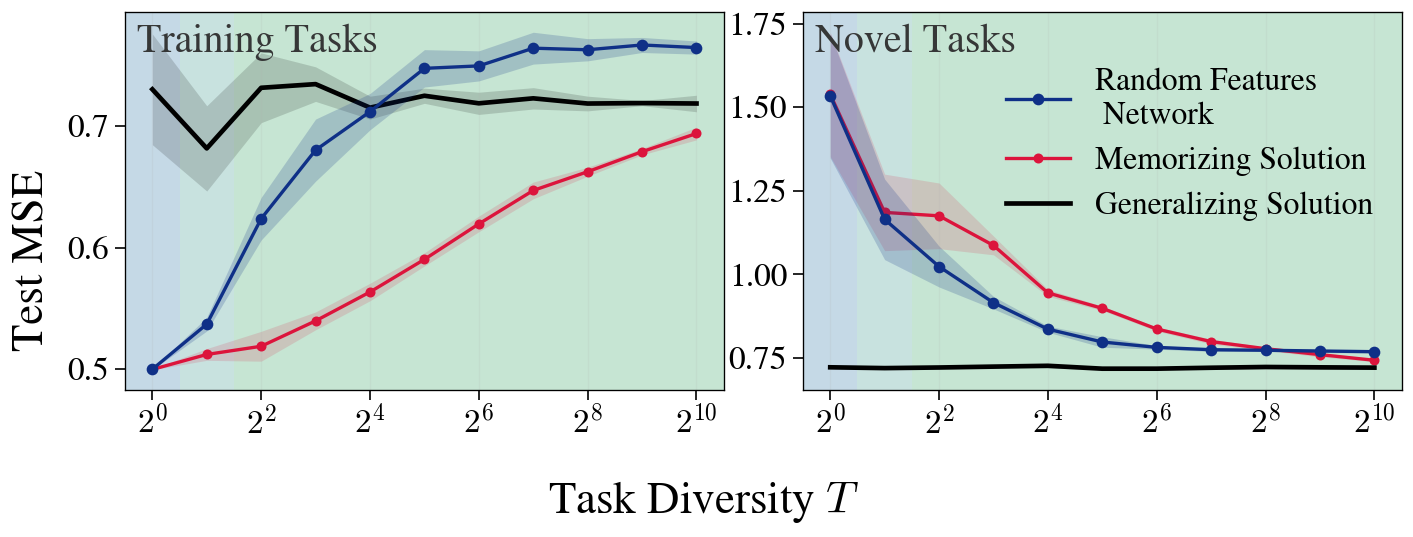

In [56]:
FIGDIR = os.path.join(RESULTPATH, "figs")
os.makedirs(FIGDIR, exist_ok=True)

fig, axs = plot_T_endpoints(runs, SWEEP_TS, SIDES, yscale=YSCALE, ylim=YLIM, band=SD_BAND,
                            oracle_band=ORA_BAND, align=ALIGN, align_base=ALIGN_BASE, floor=FLOOR,
                            floor_dist=FLOOR_DIST, floor_band=FLOOR_BAND, legend_loc=LEGEND_LOC,
                            legend_panel=LEGEND_PANEL, xlabel=XLABEL, top_free=TOP_FREE, fontsize=FONTSIZE+4,)
                            # box=param_text(CONFIG) if PARAM_BOX else None)
stem = os.path.join(FIGDIR, f"updated_taskdiv_rf_figT_{TAG}_{'-'.join(SIDES)}")
fig.savefig(stem + ".pdf", bbox_inches="tight")
fig.savefig(stem + ".png", dpi=200, bbox_inches="tight")
print("saved", stem + ".{pdf,png}")
plt.show()

saved /content/drive/MyDrive/results/figs/rf_newfig4_figT_d8p15e0.25_sx0.03125_normal_M16384_b256_w1.5_id-ood.{pdf,png}


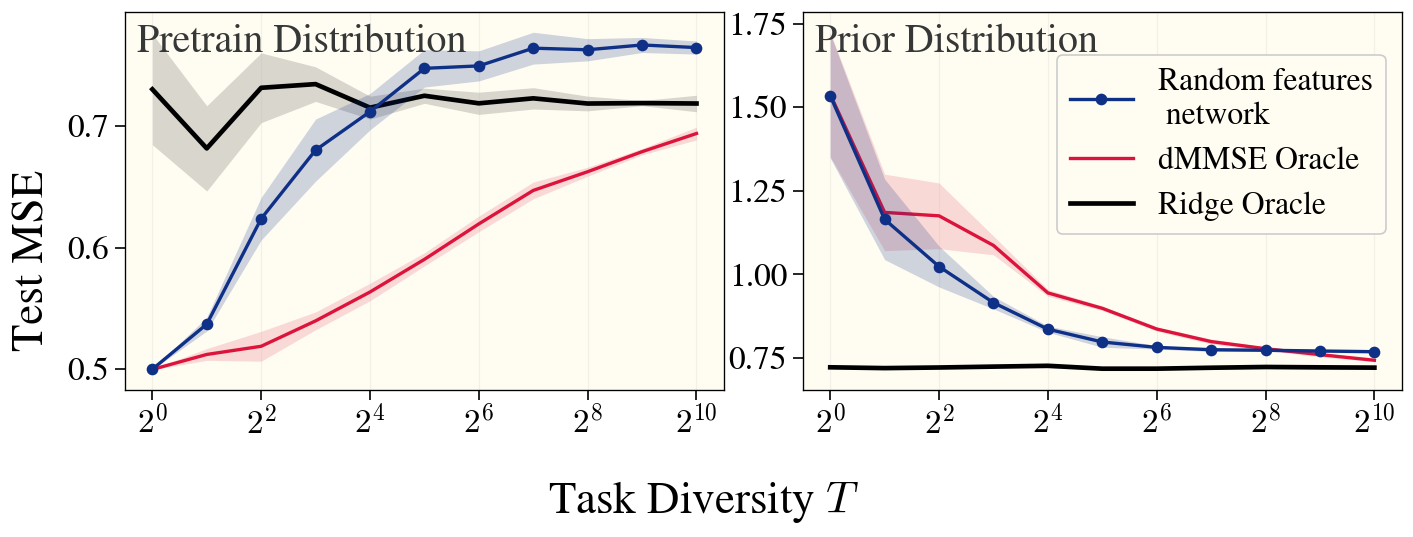

In [ ]:
FIGDIR = os.path.join(RESULTPATH, "figs")
os.makedirs(FIGDIR, exist_ok=True)

fig, axs = plot_T_endpoints(runs, SWEEP_TS, SIDES, yscale=YSCALE, ylim=YLIM, band=SD_BAND,
                            oracle_band=ORA_BAND, align=ALIGN, align_base=ALIGN_BASE, floor=FLOOR,
                            floor_dist=FLOOR_DIST, floor_band=FLOOR_BAND, legend_loc=LEGEND_LOC,
                            legend_panel=LEGEND_PANEL, xlabel=XLABEL, top_free=TOP_FREE, fontsize=FONTSIZE+4,)
                            # box=param_text(CONFIG) if PARAM_BOX else None)
stem = os.path.join(FIGDIR, f"rf_newfig4_figT_{TAG}_{'-'.join(SIDES)}")
fig.savefig(stem + ".pdf", bbox_inches="tight")
fig.savefig(stem + ".png", dpi=200, bbox_inches="tight")
print("saved", stem + ".{pdf,png}")
plt.show()

In [ ]:
# The numbers behind the figure, raw (no pool alignment); +- is the SD across the pools at each T.
def endpoint_kind(rs):
    avg = sum(bool(r.get("avg_curve")) for r in rs)
    return "averaged" if avg == len(rs) else ("last eval" if avg == 0 else f"{avg}/{len(rs)} avg")

for label, recs in runs:
    print(label)
    head = f"{'T':>5} {'runs':>4} {'endpoint':>9}"
    for s in SIDES:
        head += f" | {s.upper() + ' model':>17} {'floor3':>7} {'dMMSE':>7} {'Ridge':>7}"
    print(head)
    for T in sweep_Ts([(label, recs)], SWEEP_TS):
        rs = [r for r in recs if r["T"] == T and r.get("curve")]
        line = f"{T:>5} {len(rs):>4} {endpoint_kind(rs):>9}"
        for s in SIDES:
            v = np.array([final_point(r)[s] for r in rs], float)
            sd = v.std(ddof=1) if v.size > 1 else 0.0
            f3 = np.mean([FLOOR3(r, s) for r in rs])
            dm = np.mean([r["oracles"][f"dmmse_{s}"] for r in rs])
            rg = np.mean([r["oracles"][f"ridge_{s}"] for r in rs])
            line += f" | {v.mean():>8.4f} +- {sd:<6.4f} {f3:>7.4f} {dm:>7.4f} {rg:>7.4f}"
        print(line)